In [110]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [111]:
path = 'Asm5/Data/preschool_dataset.csv'
preschool_df = pd.read_csv(path)

In [112]:
preschool_df.columns

Index(['Child_ID', 'Age in months', 'Gender', 'Learning_Level',
       'Special_Needs', 'Attention_Span', 'Activity_Type', 'Difficulty_Level',
       'Duration', 'Engagement_Score', 'Resource_Efficiency', 'Teacher_ID',
       'Learning_Gain'],
      dtype='str')

In [113]:
display(preschool_df)

,Child_ID,Age in months,Gender,Learning_Level,Special_Needs,Attention_Span,Activity_Type,Difficulty_Level,Duration,Engagement_Score,Resource_Efficiency,Teacher_ID,Learning_Gain
0,C0102,71,Female,Low,0,8.31,Reading,Hard,13,0.44,0.94,T032,8.61
1,C0435,55,Female,Medium,0,24.64,Art,Medium,42,0.45,0.87,T027,9.45
2,C0348,39,Female,Medium,0,6.92,Art,Medium,48,0.77,0.21,T030,6.49
3,C0270,42,Female,Low,0,16.78,Math,Medium,29,0.50,0.74,T018,7.71
4,C0106,36,Male,Medium,0,17.53,Reading,Easy,22,0.72,0.44,T047,4.06
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,C0396,42,Female,Low,0,10.83,Math,Medium,14,0.39,0.52,T041,1.86
2996,C0158,46,Female,Low,0,9.53,Reading,Hard,12,0.41,0.41,T011,9.65
2997,C0070,39,Female,Low,0,7.58,Music,Easy,37,0.79,0.94,T002,0.95
2998,C0446,60,Female,Low,0,23.92,Art,Medium,35,0.91,0.94,T014,7.69


In [114]:
#see if there is corelation of attention span and engagement
attention_correlation = preschool_df.Attention_Span.corr(preschool_df.Engagement_Score)
attention_correlation
#no correlation

np.float64(0.002927696820701736)

In [154]:
#Find which activites has the most attention span and Engagement_Score
#if engagmenr_score has any correlation with learning gain
#look at resource efficiency and difficulty_level
#how much does age has an effect on these

In [155]:
preschool_df['Child_ID'].count()
#3000 children in this dataset

np.int64(3000)

In [156]:
male_child = len(preschool_df[preschool_df['Gender'] == 'Male'])
female_child = len(preschool_df[preschool_df['Gender'] == 'Female'])

print('male child' ,male_child)
print('female child' ,female_child)

male child 1497
female child 1503


In [157]:
#activities type 
Activity_type = preschool_df.Activity_Type.value_counts()
Activity_type

Activity_Type
Reading         637
Math            608
Art             596
Music           588
Sensory Play    571
Name: count, dtype: int64

In [158]:
Activity_type.max() #don't know why its not showing Reading

np.int64(637)

In [159]:
#activities that has most Attention_Span
most_attention = preschool_df.loc[preschool_df.Attention_Span.idxmax(), 'Activity_Type']
most_attention

'Math'

In [160]:
#chlid that has the most Attention_Span
most_attention_child = preschool_df.loc[preschool_df.Attention_Span.idxmax()]
most_attention_child

Child_ID               C0317
Age in months             37
Gender                  Male
Learning_Level             2
Special_Needs              0
Attention_Span         24.99
Activity_Type           Math
Difficulty_Level           3
Duration                  44
Engagement_Score        0.63
Resource_Efficiency     0.63
Teacher_ID              T024
Learning_Gain           9.19
Name: 247, dtype: object

In [161]:
#adverage attention span for each activities
print(preschool_df["Attention_Span"].dtype) #checking types

float64


In [162]:
math_attention_adv = preschool_df.loc[preschool_df["Activity_Type"] == "Math", "Attention_Span"]
print(math_attention_adv.mean())

15.177631578947368


In [163]:
#activities that has least Attention_Span
least_attention = preschool_df.loc[preschool_df.Attention_Span.idxmin(), 'Activity_Type']
least_attention

'Sensory Play'

In [164]:
#chlid that has the least Attention_Span
least_attention = preschool_df.loc[preschool_df.Attention_Span.idxmin()]
least_attention

Child_ID                      C0248
Age in months                    43
Gender                       Female
Learning_Level                    3
Special_Needs                     0
Attention_Span                  5.0
Activity_Type          Sensory Play
Difficulty_Level                  1
Duration                         17
Engagement_Score               0.83
Resource_Efficiency            0.92
Teacher_ID                     T039
Learning_Gain                  0.49
Name: 1181, dtype: object

In [165]:
preschool_df.describe()
#trying out describe 

,Age in months,Special_Needs,Attention_Span,Duration,Engagement_Score,Resource_Efficiency,Learning_Gain
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,53.616000,0.092667,14.961093,34.513333,0.651160,0.604360,5.053203
std,10.277244,0.290013,5.814003,14.422430,0.202279,0.234415,2.874874
min,36.000000,0.000000,5.000000,10.000000,0.300000,0.200000,0.010000
25%,45.000000,0.000000,9.880000,22.000000,0.480000,0.400000,2.610000
50%,54.000000,0.000000,14.795000,35.000000,0.650000,0.600000,5.070000
75%,62.000000,0.000000,20.100000,47.000000,0.830000,0.810000,7.560000
max,71.000000,1.000000,24.990000,59.000000,1.000000,1.000000,10.000000


In [166]:
#activity that has most Engagement_Score
avg_engagement = preschool_df.groupby('Activity_Type')['Engagement_Score'].mean()
avg_engagement

Activity_Type
Art             0.646594
Math            0.642122
Music           0.647279
Reading         0.651837
Sensory Play    0.668792
Name: Engagement_Score, dtype: float64

In [167]:
most_engaging = avg_engagement.idxmax()
most_engaging

'Sensory Play'

In [168]:
least_engaging = avg_engagement.idxmin()
least_engaging

'Math'

In [169]:
#correlation of resource effiency and difficulty_level
#convert Difficulty_Level to 1-3 scale, 1=low; 3=high
mapping = {'Easy':1,'Medium':2,'Hard':3}
preschool_df['Difficulty_Level'] = preschool_df['Difficulty_Level'].replace (mapping)

In [170]:
display(preschool_df)

,Child_ID,Age in months,Gender,Learning_Level,Special_Needs,Attention_Span,Activity_Type,Difficulty_Level,Duration,Engagement_Score,Resource_Efficiency,Teacher_ID,Learning_Gain
0,C0102,71,Female,1,0,8.31,Reading,3,13,0.44,0.94,T032,8.61
1,C0435,55,Female,2,0,24.64,Art,2,42,0.45,0.87,T027,9.45
2,C0348,39,Female,2,0,6.92,Art,2,48,0.77,0.21,T030,6.49
3,C0270,42,Female,1,0,16.78,Math,2,29,0.50,0.74,T018,7.71
4,C0106,36,Male,2,0,17.53,Reading,1,22,0.72,0.44,T047,4.06
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,C0396,42,Female,1,0,10.83,Math,2,14,0.39,0.52,T041,1.86
2996,C0158,46,Female,1,0,9.53,Reading,3,12,0.41,0.41,T011,9.65
2997,C0070,39,Female,1,0,7.58,Music,1,37,0.79,0.94,T002,0.95
2998,C0446,60,Female,1,0,23.92,Art,2,35,0.91,0.94,T014,7.69


In [171]:
#resource effiency and difficulty_level
res_diff_lvl = preschool_df.groupby('Difficulty_Level')['Resource_Efficiency'].mean()
res_diff_lvl
#the more difficult the activites, the less resource efficiency they are

Difficulty_Level
1    0.613401
2    0.600632
3    0.599284
Name: Resource_Efficiency, dtype: float64

In [172]:
#correlation of Difficulty_Level and Resource_Efficiency
res_diff_lvl_corr = preschool_df.Resource_Efficiency.corr(preschool_df.Difficulty_Level)
res_diff_lvl_corr
#not much correlation

np.float64(-0.0243263462889493)

In [173]:
#correlation of learning gain and Difficulty_Level
learn_gain_diff_lvl_corr = preschool_df.Learning_Gain.corr(preschool_df.Difficulty_Level)
learn_gain_diff_lvl_corr

np.float64(-0.023747745337969643)

In [174]:
#learning lvl vs learning gain
mapping_learning = {'Low':1,'Medium':2,'High':3}
preschool_df['Learning_Level'] = preschool_df['Learning_Level'].replace (mapping_learning)
learning_lvl_gain_corr=preschool_df.Learning_Gain.corr(preschool_df.Learning_Level)
learning_lvl_gain_corr
#not much correlation

np.float64(-0.01011683957535859)

In [175]:
display(preschool_df)

,Child_ID,Age in months,Gender,Learning_Level,Special_Needs,Attention_Span,Activity_Type,Difficulty_Level,Duration,Engagement_Score,Resource_Efficiency,Teacher_ID,Learning_Gain
0,C0102,71,Female,1,0,8.31,Reading,3,13,0.44,0.94,T032,8.61
1,C0435,55,Female,2,0,24.64,Art,2,42,0.45,0.87,T027,9.45
2,C0348,39,Female,2,0,6.92,Art,2,48,0.77,0.21,T030,6.49
3,C0270,42,Female,1,0,16.78,Math,2,29,0.50,0.74,T018,7.71
4,C0106,36,Male,2,0,17.53,Reading,1,22,0.72,0.44,T047,4.06
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,C0396,42,Female,1,0,10.83,Math,2,14,0.39,0.52,T041,1.86
2996,C0158,46,Female,1,0,9.53,Reading,3,12,0.41,0.41,T011,9.65
2997,C0070,39,Female,1,0,7.58,Music,1,37,0.79,0.94,T002,0.95
2998,C0446,60,Female,1,0,23.92,Art,2,35,0.91,0.94,T014,7.69


In [176]:
#finding correlation of data
corr1=preschool_df.Attention_Span.corr(preschool_df.Learning_Gain)
corr1

np.float64(0.04133504587181727)

In [177]:
corr2=preschool_df.Learning_Level.corr(preschool_df.Learning_Gain)
corr2

np.float64(-0.010116839575358591)

In [178]:
corr3=preschool_df.Engagement_Score.corr(preschool_df.Learning_Gain)
corr3

np.float64(0.010793527159669941)

In [179]:
corr4=preschool_df["Age in months"].corr(preschool_df.Learning_Gain)
corr4

np.float64(0.037529548364174825)

In [180]:
#no strong correlation in learning_gain and other information

In [181]:
attention_avg = preschool_df.groupby("Activity_Type")["Attention_Span"].mean()
print(attention_avg)

Activity_Type
Art             15.084799
Math            15.177632
Music           14.882449
Reading         14.888776
Sensory Play    14.763065
Name: Attention_Span, dtype: float64


In [182]:
learning_gain_avg = preschool_df.groupby("Activity_Type")["Learning_Gain"].mean()
print(learning_gain_avg)

Activity_Type
Art             5.145721
Math            5.101941
Music           5.033452
Reading         5.037206
Sensory Play    4.942925
Name: Learning_Gain, dtype: float64


In [206]:
#prepareing for histogram

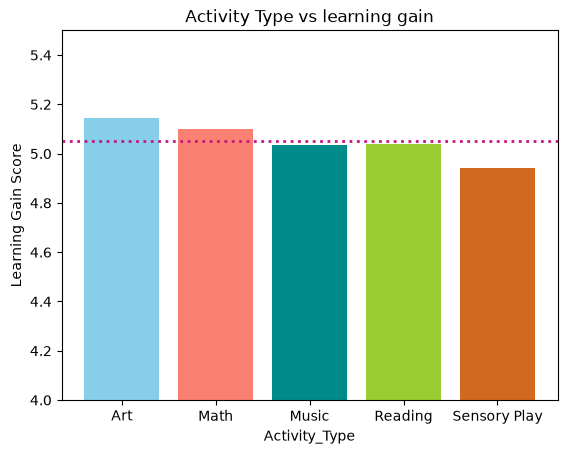

In [217]:
plt.bar(learning_gain_avg.index, learning_gain_avg.values, color=["skyblue", "salmon", "darkcyan","yellowgreen","chocolate"])

plt.ylim([4,5.5])

plt.xlabel('Activity_Type')
plt.ylabel('Learning Gain Score')
plt.title('Activity Type vs learning gain')
plt.axhline(preschool_df.Learning_Gain.mean(), color="mediumvioletred", linestyle='dotted', linewidth=2)
plt.show()